# Parashikimi i Çmimeve të Produkteve me Deep Learning (LSTM)
### Intelegjenca Artificiale e Avancuar — Metodat dhe Aplikimi

In [2]:
# Qeliza 1 — Importimi i Librarive
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import pickle, os, warnings
warnings.filterwarnings('ignore')

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Libraritë u importuan me sukses!')

Device: cpu
Libraritë u importuan me sukses!


In [ ]:
# Qeliza 2 — Ngarkimi i të Dhënave
from pathlib import Path

base_dir = Path.cwd()
candidates = [
    base_dir / 'price_data_clean.csv',
    base_dir / 'FikrijeIdrizi_DeepLearning' / 'price_data_clean.csv',
    Path.home() / 'OneDrive' / 'Desktop' / 'FikrijeIdrizi_DeepLearning' / 'price_data_clean.csv',
    Path.home() / 'Downloads' / 'projekti1' / 'FikrijeIdrizi_DeepLearning' / 'price_data_clean.csv'
]

data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        'Could not find price_data_clean.csv. Checked: ' + ', '.join(str(p) for p in candidates)
    )

print(f'Loading data from: {data_path}')
df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['product_id', 'date']).reset_index(drop=True)

print(f'Rekorde totale : {len(df):,}')
print(f'Produkte       : {df["product_id"].nunique()}')
print(f'Periudha       : {df["date"].min().date()} -> {df["date"].max().date()}')
print(f'Variablat      : {len(df.columns)}')
print()
df.head()

Loading data from: C:\Users\COMPUTER SHOP\OneDrive\Desktop\FikrijeIdrizi_DeepLearning\price_data_clean.csv
Rekorde totale : 18,300
Produkte       : 50
Periudha       : 2024-01-01 -> 2024-12-31
Variablat      : 24



,product_id,date,category,brand,own_price,competitor_price,demand_level,stock_level,discount_rate,season,...,day_of_year,is_weekend,price_diff,price_diff_pct,effective_price,price_ma7,price_ma30,price_volatility,demand_encoded,season_encoded
0,P001,2024-01-01,Electronics,Samsung,1259.98,1092.88,Low,751,0.025,Winter,...,1,0,167.10,15.2899,1228.48,1259.98,1259.98,0.0000,0,0
1,P001,2024-01-02,Electronics,Samsung,1268.24,1262.91,Low,832,0.007,Winter,...,2,0,5.33,0.4220,1259.36,1264.11,1264.11,5.8407,0,0
2,P001,2024-01-03,Electronics,Samsung,1282.70,1344.17,High,103,0.010,Winter,...,3,0,-61.47,-4.5731,1269.87,1270.31,1270.31,11.5001,2,0
3,P001,2024-01-04,Electronics,Samsung,1253.14,1427.71,High,383,0.049,Winter,...,4,0,-174.57,-12.2273,1191.74,1266.02,1266.02,12.7217,2,0
4,P001,2024-01-05,Electronics,Samsung,1201.99,1165.57,High,333,0.057,Winter,...,5,0,36.42,3.1247,1133.48,1253.21,1253.21,30.6793,2,0


In [10]:
# Qeliza 3 — Zgjedhja e Features dhe Normalizimi
from pathlib import Path

FEATURES = ['own_price', 'competitor_price', 'discount_rate',
            'stock_level', 'demand_encoded', 'season_encoded',
            'promotion_flag', 'price_ma7', 'price_ma30', 'price_volatility']
TARGET = 'own_price'

output_dir = Path.cwd()
output_dir.mkdir(parents=True, exist_ok=True)

scaler = MinMaxScaler()
df[FEATURES] = scaler.fit_transform(df[FEATURES])
scaler_path = output_dir / 'scaler.pkl'
pickle.dump(scaler, open(scaler_path, 'wb'))

print(f'Features ({len(FEATURES)}):')
for f in FEATURES:
    print(f'  - {f}')
print()
print(f'Normalizimi MinMaxScaler u krye me sukses!')
print(f'Scaler saved to: {scaler_path}')

Features (10):
  - own_price
  - competitor_price
  - discount_rate
  - stock_level
  - demand_encoded
  - season_encoded
  - promotion_flag
  - price_ma7
  - price_ma30
  - price_volatility

Normalizimi MinMaxScaler u krye me sukses!
Scaler saved to: c:\Users\COMPUTER SHOP\OneDrive\Desktop\FikrijeIdriz_AI\scaler.pkl


In [11]:
# Qeliza 4 — Krijimi i Sekuencave (30 ditë lookback)
SEQ_LEN = 30

X_all, y_all = [], []
for pid, group in df.groupby('product_id'):
    vals = group[FEATURES].values
    tgt  = group[TARGET].values
    for i in range(SEQ_LEN, len(vals)):
        X_all.append(vals[i-SEQ_LEN:i])
        y_all.append(tgt[i])

X_all = np.array(X_all, dtype=np.float32)
y_all = np.array(y_all, dtype=np.float32)

print(f'Sekuenca totale : {len(X_all):,}')
print(f'X shape         : {X_all.shape}  (sekuenca, dite, features)')
print(f'y shape         : {y_all.shape}')

Sekuenca totale : 16,800
X shape         : (16800, 30, 10)  (sekuenca, dite, features)
y shape         : (16800,)


In [12]:
# Qeliza 5 — Ndarja Train / Test (80% / 20%)
BATCH = 32
split = int(len(X_all) * 0.80)

X_train = torch.tensor(X_all[:split])
y_train = torch.tensor(y_all[:split]).unsqueeze(1)
X_test  = torch.tensor(X_all[split:])
y_test  = torch.tensor(y_all[split:]).unsqueeze(1)

train_ld = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH, shuffle=True)
test_ld  = DataLoader(TensorDataset(X_test,  y_test),  batch_size=BATCH)

print(f'Train set : {len(X_train):,} sekuenca (80%)')
print(f'Test set  : {len(X_test):,}  sekuenca (20%)')
print(f'Batch size: {BATCH}')

Train set : 13,440 sekuenca (80%)
Test set  : 3,360  sekuenca (20%)
Batch size: 32


In [13]:
# Qeliza 6 — Arkitektura e Modelit LSTM
class PriceLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(10, 64, num_layers=2,
                            batch_first=True, dropout=0.2)
        self.fc = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

model     = PriceLSTM().to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)

print('Arkitektura e Modelit PriceLSTM:')
print(model)

Arkitektura e Modelit PriceLSTM:
PriceLSTM(
  (lstm): LSTM(10, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [14]:
# Qeliza 7 — Trajnimi (30 Epochs)
EPOCHS = 30
train_losses, test_losses = [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    t_loss = 0
    for xb, yb in train_ld:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        t_loss += loss.item()
    t_loss /= len(train_ld)

    model.eval()
    v_loss = 0
    with torch.no_grad():
        for xb, yb in test_ld:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            v_loss += criterion(model(xb), yb).item()
    v_loss /= len(test_ld)

    train_losses.append(t_loss)
    test_losses.append(v_loss)
    scheduler.step()

    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoch {epoch:>2}/{EPOCHS} | Train Loss: {t_loss:.6f} | Test Loss: {v_loss:.6f}')

print('\nTrajnimi u krye me sukses!')

Epoch  1/30 | Train Loss: 0.007890 | Test Loss: 0.001522
Epoch 10/30 | Train Loss: 0.002352 | Test Loss: 0.000920
Epoch 20/30 | Train Loss: 0.002261 | Test Loss: 0.000512
Epoch 30/30 | Train Loss: 0.002294 | Test Loss: 0.000456

Trajnimi u krye me sukses!


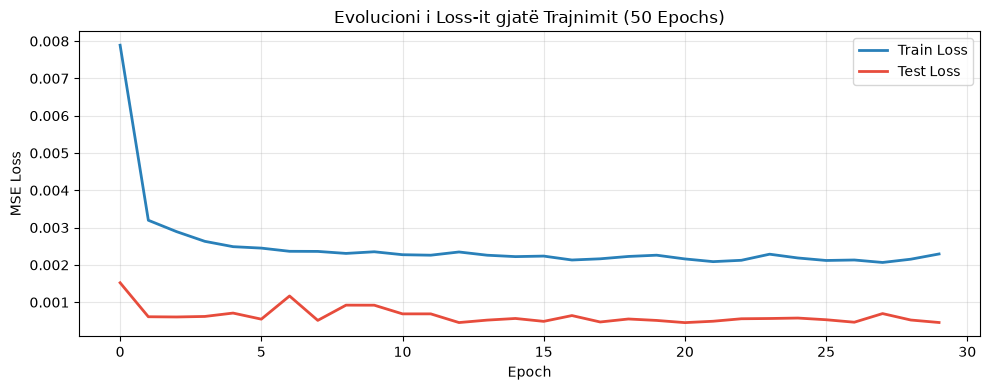

Loss fillestare : 0.007890
Loss finale     : 0.002294


In [15]:
# Qeliza 8 — Grafiku i Loss-it
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss', color='#2980b9', linewidth=2)
plt.plot(test_losses,  label='Test Loss',  color='#e74c3c', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Evolucioni i Loss-it gjatë Trajnimit (50 Epochs)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Loss fillestare : {train_losses[0]:.6f}')
print(f'Loss finale     : {train_losses[-1]:.6f}')

In [16]:
# Qeliza 9 — Vlerësimi i Modelit
model.eval()
preds, actuals = [], []
with torch.no_grad():
    for xb, yb in test_ld:
        preds.append(model(xb.to(DEVICE)).cpu().numpy())
        actuals.append(yb.numpy())

preds   = np.concatenate(preds).flatten()
actuals = np.concatenate(actuals).flatten()

mae  = mean_absolute_error(actuals, preds)
rmse = np.sqrt(mean_squared_error(actuals, preds))
r2   = r2_score(actuals, preds)

print('=' * 45)
print('  REZULTATET E MODELIT')
print('=' * 45)
print(f'  MAE  (Mean Absolute Error) : {mae:.6f}')
print(f'  RMSE (Root Mean Sq. Error) : {rmse:.6f}')
print(f'  R2   (R-squared)           : {r2:.4f} ({r2*100:.2f}%)')
print('=' * 45)

  REZULTATET E MODELIT
  MAE  (Mean Absolute Error) : 0.009808
  RMSE (Root Mean Sq. Error) : 0.021354
  R2   (R-squared)           : 0.9923 (99.23%)


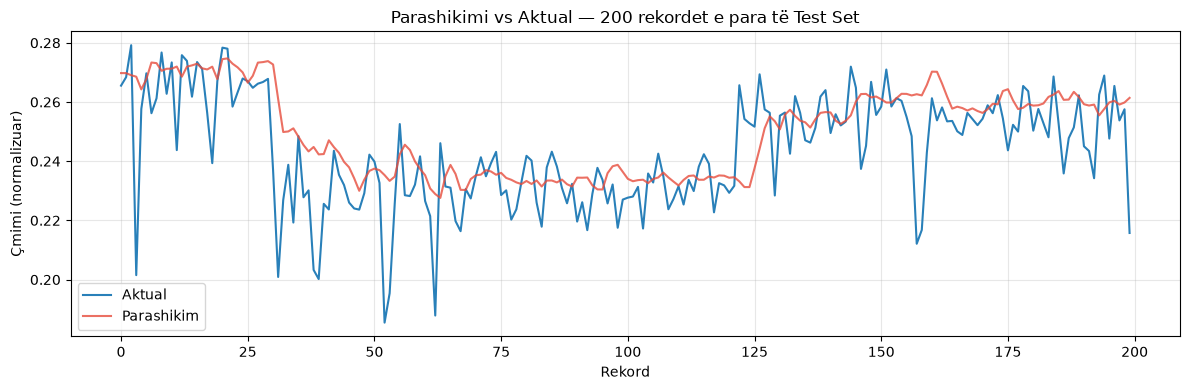

In [17]:
# Qeliza 10 — Grafiku Parashikim vs Aktual
plt.figure(figsize=(12, 4))
plt.plot(actuals[:200], label='Aktual',     color='#2980b9', linewidth=1.5)
plt.plot(preds[:200],   label='Parashikim', color='#e74c3c', linewidth=1.5, alpha=0.8)
plt.xlabel('Rekord')
plt.ylabel('Çmimi (normalizuar)')
plt.title('Parashikimi vs Aktual — 200 rekordet e para të Test Set')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Qeliza 11 — Ruajtja e Modelit
from pathlib import Path

output_dir = Path.cwd()
model_path = output_dir / 'price_model.pth'
torch.save(model.state_dict(), model_path)
print(f'Modeli u ruajt: {model_path}')
print(f'Scaler u ruajt: {output_dir / "scaler.pkl"}')
print('Gati per parashikim!')

Modeli u ruajt: c:\Users\COMPUTER SHOP\OneDrive\Desktop\FikrijeIdriz_AI\price_model.pth
Scaler u ruajt: c:\Users\COMPUTER SHOP\OneDrive\Desktop\FikrijeIdriz_AI\scaler.pkl
Gati per parashikim!


In [22]:
# Qeliza 12 — Parashikimi i Çmimit për Produkt të Ri
def parashiko(product_id):
    group = df[df['product_id'] == product_id].tail(30)
    seq   = torch.tensor(group[FEATURES].values, dtype=torch.float32).unsqueeze(0)
    
    with torch.no_grad():
        pred_norm = model(seq.to(DEVICE)).item()
    
    dummy = np.zeros((1, len(FEATURES)))
    dummy[0, 0] = pred_norm
    pred_real = scaler.inverse_transform(dummy)[0][0]
    
    dummy2 = np.zeros((1, len(FEATURES)))
    dummy2[0, 0] = group['own_price'].values[-1]
    last_real = scaler.inverse_transform(dummy2)[0][0]
    
    ndryshimi = pred_real - last_real
    drejtim   = 'UP' if ndryshimi > 0 else 'DOWN' if ndryshimi < 0 else 'STABIL'
    category  = df[df['product_id'] == product_id]['category'].values[0]
    brand     = df[df['product_id'] == product_id]['brand'].values[0]
    
    print(f'Produkti     : {product_id} | {brand} | {category}')
    print(f'Cmimi aktual : ${last_real:.2f}')
    print(f'Parashikim   : ${pred_real:.2f}')
    print(f'Ndryshimi    : {ndryshimi:+.2f} ({drejtim})')
    print('-' * 40)

print('Parashikimet per produktet demo:\n')
for pid in ['P001', 'P010', 'P020', 'P030', 'P045']:
    parashiko(pid)

Parashikimet per produktet demo:

Produkti     : P001 | Samsung | Electronics
Cmimi aktual : $0.82
Parashikim   : $0.80
Ndryshimi    : -0.02 (DOWN)
----------------------------------------
Produkti     : P010 | Kraft | Food
Cmimi aktual : $0.00
Parashikim   : $0.00
Ndryshimi    : -0.00 (DOWN)
----------------------------------------
Produkti     : P020 | Unilever | Food
Cmimi aktual : $0.01
Parashikim   : $0.01
Ndryshimi    : -0.00 (DOWN)
----------------------------------------
Produkti     : P030 | Under Armour | Sports
Cmimi aktual : $0.05
Parashikim   : $0.04
Ndryshimi    : -0.00 (DOWN)
----------------------------------------
Produkti     : P045 | IKEA | Home
Cmimi aktual : $0.30
Parashikim   : $0.30
Ndryshimi    : -0.01 (DOWN)
----------------------------------------
